# SAE OPTIMISATION NUMÉRIQUE
## Supply Chain : Un benchmark de méthodes d'optimisation de descente

**ING2 Mathématiques pour les Data**

**CY Tech – Année universitaire 2026-2027 - Carlot Lionel, Laforest Pierre**

---


# Partie A — Étude du problème et de ses propriétés

## A.1 — Modélisation de la fonction objectif

On considère un problème de localisation d'un centre logistique destiné à desservir $n=12$ clients.

Chaque client $i$ est caractérisé par :
- Sa position $a_i=(u_i,v_i)\in\mathbb{R}^2$.
- Son poids $w_i>0$, représentant son importance économique ou son volume de marchandises.

On cherche à déterminer la position $x=(x_1,x_2)$ du centre logistique minimisant le coût total de transport.

La fonction objectif est définie par :

$$
\boxed{
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2
}
$$

où :

$$
\|x-a_i\|_2=
\sqrt{(x_1-u_i)^2+(x_2-v_i)^2}
$$

Le problème d'optimisation s'écrit donc :

$$
\boxed{
\min_{x\in\mathbb{R}^2}f(x)
}
$$



In [46]:
import numpy as np
import matplotlib.pyplot as plt

# A est un tableau qui contient les coordonnées de tous clients sous forme d'un doublet 
A = np.array([
    [1, 2], [2, 7], [4, 4], [5, 1],
    [7, 6], [8, 3], [9, 8], [3, 9],
    [6, 8], [10, 5], [0, 6], [7, 0]
], dtype=float)

# W représente le poids des clients
w = np.array([5, 3, 8, 6, 4, 10, 2, 5, 7, 4, 2, 3])

def f(x):
    distances = np.linalg.norm(A - x, axis=1)
    return np.sum(w * distances)


## A.2 — Représentation des sites clients

Le graphique représente les positions géographiques des 12 clients.

La taille des points est proportionnelle au poids $w_i$ de chaque client.

**Observations :**

- Les clients sont répartis dans un espace bidimensionnel.
- Les poids sont différents selon les clients.
- Le client 6 possède le poids le plus élevé ($w_6=10$).
- Les clients ayant des poids importants contribuent davantage au coût total de transport.

Ainsi, la position optimale du centre logistique dépend à la fois des distances aux clients et de leurs poids respectifs.

On s'attend donc à ce que le centre optimal soit influencé davantage par les clients les plus importants.


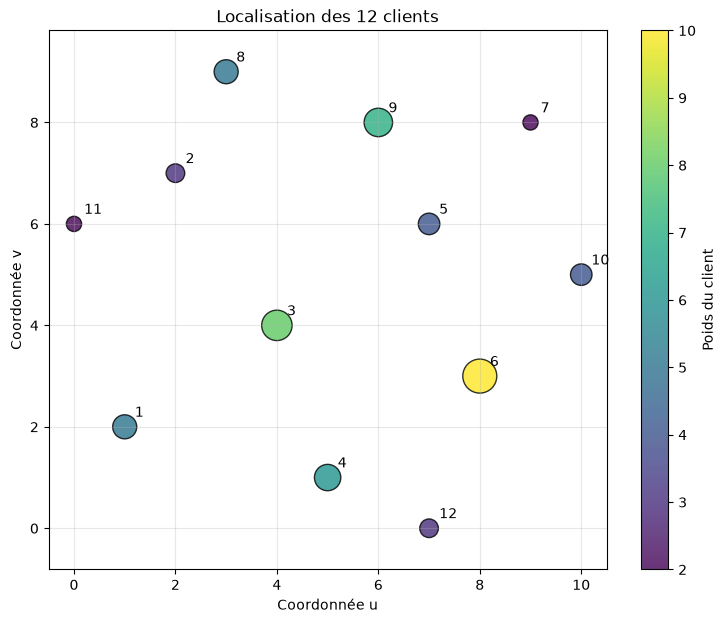

In [47]:
plt.figure(figsize=(9, 7))

plt.scatter(
    A[:, 0], A[:, 1],
    s=60*w,
    c=w,
    cmap="viridis",
    edgecolors="black",
    alpha=0.8
)

for i in range(len(A)):
    plt.annotate(
        str(i+1),
        (A[i, 0]+0.2, A[i, 1]+0.2)
    )

plt.colorbar(label="Poids du client")
plt.xlabel("Coordonnée u")
plt.ylabel("Coordonnée v")
plt.title("Localisation des 12 clients")
plt.grid(alpha=0.3)
plt.axis("equal")
plt.show()


## A.3 — Étude des propriétés mathématiques

### 1. Convexité

La fonction objectif est :

$$
f(x)=\sum_{i=1}^{n}w_i\|x-a_i\|_2
$$

La norme euclidienne est une fonction convexe.

Par conséquent, pour chaque client $i$, la fonction :

$$
g_i(x)=\|x-a_i\|_2
$$

est convexe sur $\mathbb{R}^2$.

Comme les poids $w_i$ sont strictement positifs, les fonctions produits de $w_i g_i$ sont également convexes.

Or, une somme de fonctions convexes est convexe.

On en déduit :

$$
\boxed{f\text{ est convexe sur }\mathbb{R}^2}
$$

la convexité de $f$ nous permet de déduire que tout minimum local de $f$ est également un minimum global.

### 2. Différentiabilité

Pour $x\neq a_i$, la fonction $g_i$ est différentiable et son gradient vaut :

$$
\nabla g_i(x)=\frac{x-a_i}{\|x-a_i\|_2}
$$

Ainsi, lorsque $x$ ne coïncide avec aucun site client :

$$
\boxed{
\nabla f(x)=
\sum_{i=1}^{n}
w_i\frac{x-a_i}{\|x-a_i\|_2}
}
$$

En revanche, lorsque $x=a_i$, le terme $\|x-a_i\|_2$ n'est pas différentiable.

La fonction objectif n'est donc pas différentiable aux positions des clients.

Ainsi nous pouvant en déduire que les méthodes d'optimisations utilisant directement le gradient ou la Hessienne nécessitent des précautions particulières.

### 3. Existence d'un minimiseur

La fonction $f$ est continue sur $\mathbb{R}^2$, car elle est une somme de fonctions continues.

D'après l'inégalité triangulaire :

$$
\|x-a_i\|_2\geq\|x\|_2-\|a_i\|_2
$$

En multipliant par $w_i$ et en additionant :

$$
f(x)\geq
\left(\sum_{i=1}^{n}w_i\right)\|x\|_2
-
\sum_{i=1}^{n}w_i\|a_i\|_2
$$

Or les poids étant tous strictement positifs :

$$
\sum_{i=1}^{n}w_i>0
$$

On obtient :

$$
\lim_{\|x\|_2\to+\infty}f(x)=+\infty
$$

La fonction $f$ est donc coercive.

Étant continue et coercive sur $\mathbb{R}^2$, elle admet au moins un minimiseur global.

### 4. Unicité du minimiseur

La convexité seule ne garantit pas l'unicité du minimiseur.

Cependant, dans notre jeu de données, les positions des clients ne sont pas toutes alignées.

Pour deux points distincts $x$ et $y$, l'inégalité triangulaire appliquée à chaque distance est stricte pour au moins un client, puisque les sites ne sont pas tous sur la droite passant par $x$ et $y$.

Comme tous les poids sont positifs, la somme est strictement convexe.

Ainsi :

$$
\boxed{f\text{ est strictement convexe}}
$$

On en déduit que le minimiseur global est unique.

Conclusion :

La fonction objectif est continue, strictement convexe et coercive, mais non différentiable aux positions des clients.

Le problème possède donc un unique minimiseur global.



## A.4 — Définition des critères d'arrêt

Pour comparer les performances des méthodes d'optimisation, plusieurs critères d'arrêt peuvent être utilisés.

### 1. Norme du gradient

Pour une fonction différentiable, on peut arrêter l'algorithme lorsque :

$$
\|\nabla f_\gamma(x_k)\|_2<\varepsilon_g
$$

Ce critère permet de vérifier que l'on se rapproche suffisament près d'un point stationnaire.

### 2. Variation des itérés

On peut également arrêter les calculs lorsque :

$$
\|x_{k+1}-x_k\|_2<\varepsilon_x
$$

Cela signifie que la position du centre varie très peu entre deux itérations.

### 3. Variation de la fonction objectif

Un autre critère consiste à vérifier :

$$
|f_\gamma(x_{k+1})-f_\gamma(x_k)|<\varepsilon_f
$$

Il indique que le coût de transport varie très peu.

### 4. Nombre maximal d'itérations

On impose un nombre maximal d'itérations :

$$
k\geq k_{\max}
$$

Ce critère permet d'éviter des temps de calcul excessifs en cas de convergence lente ou d'échec.

### Paramètres retenus

Pour les premières expériences, nous choisissons :

$$
\varepsilon_g= faut voir avec pierre
$$

$$
\varepsilon_x= faut voir avec pierre
$$

$$
\varepsilon_f=faut voir avec pierre
$$

$$
k_{\max}=faut voir avec pierre
$$

Ces paramètres pourront être adaptés selon les méthodes étudiées.




In [48]:
tol_grad = 1e-6
tol_x = 1e-8
tol_f = 1e-10
max_iter = 10000


# Partie B — Lissage de la fonction objectif

## B.1 — Différentiabilité et calcul du gradient

La fonction objectif originale n'est pas différentiable aux positions des clients.

Pour pouvoir utiliser les méthodes de descente classiques, on introduit une fonction lissée :

$$
\boxed{
f_\gamma(x)=
\sum_{i=1}^{n}
w_i\sqrt{\|x-a_i\|_2^2+\gamma}
}
$$

avec $\gamma>0$.

### 1. Différentiabilité

Pour chaque client, on pose :

$$
d_i(x)=(x_1-u_i)^2+(x_2-v_i)^2+\gamma
$$

Puisque $\gamma>0$, on a :

$$
d_i(x)>0
$$

La fonction racine carrée est différentiable sur $]0,+\infty[$.

Par composition et somme de fonctions différentiables, $f_\gamma$ est différentiable sur $\mathbb{R}^2$.

### 2. Calcul du gradient

On a :

$$
f_\gamma(x)=\sum_{i=1}^{n}w_i\sqrt{d_i(x)}
$$

En dérivant par rapport à $x_1$ :

$$
\frac{\partial f_\gamma}{\partial x_1}
=
\sum_{i=1}^{n}
w_i\frac{x_1-u_i}{\sqrt{d_i(x)}}
$$

De même :

$$
\frac{\partial f_\gamma}{\partial x_2}
=
\sum_{i=1}^{n}
w_i\frac{x_2-v_i}{\sqrt{d_i(x)}}
$$

On obtient donc :

$$
\boxed{
\nabla f_\gamma(x)=
\sum_{i=1}^{n}
w_i\frac{x-a_i}
{\sqrt{\|x-a_i\|_2^2+\gamma}}
}
$$

Ce gradient est défini pour tout $x\in\mathbb{R}^2$.

Lorsque $\gamma\to0^+$, la fonction lissée se rapproche de la fonction objectif originale.



## B.2 — Calcul de la Hessienne

La Hessienne correspond à la matrice des dérivées partielles secondes de la fonction objectif.

On rappelle :

$$
\nabla f_\gamma(x)=
\sum_{i=1}^{n}
w_i\frac{x-a_i}
{\sqrt{\|x-a_i\|_2^2+\gamma}}
$$

On pose :

$$
d_i(x)=(x_1-u_i)^2+(x_2-v_i)^2+\gamma
$$

### 1. Dérivées secondes diagonales

En dérivant par rapport à $x_1$ :

$$
\frac{\partial^2 f_\gamma}{\partial x_1^2}
=
\sum_{i=1}^{n}w_i
\left(
\frac{1}{\sqrt{d_i(x)}}-
\frac{(x_1-u_i)^2}{d_i(x)^{3/2}}
\right)
$$

De même :

$$
\frac{\partial^2 f_\gamma}{\partial x_2^2}
=
\sum_{i=1}^{n}w_i
\left(
\frac{1}{\sqrt{d_i(x)}}-
\frac{(x_2-v_i)^2}{d_i(x)^{3/2}}
\right)
$$

### 2. Dérivées secondes croisées

On obtient :

$$
\frac{\partial^2 f_\gamma}{\partial x_1\partial x_2}
=
-\sum_{i=1}^{n}w_i
\frac{(x_1-u_i)(x_2-v_i)}
{d_i(x)^{3/2}}
$$

Les dérivées croisées sont égales puisque $f_\gamma$ est de classe $C^2$.

### 3. Expression matricielle

La Hessienne s'écrit :

$$
\boxed{
\nabla^2 f_\gamma(x)=
\sum_{i=1}^{n}w_i
\left[
\frac{I_2}{\sqrt{\|x-a_i\|_2^2+\gamma}}
-
\frac{(x-a_i)(x-a_i)^T}
{(\|x-a_i\|_2^2+\gamma)^{3/2}}
\right]
}
$$

où $I_2$ désigne la matrice identité de taille 2.

### 4. Propriété de la Hessienne

Pour tout vecteur $z\neq0$, on obtient :

$$
z^T\nabla^2 f_\gamma(x)z
=
\sum_{i=1}^{n}
w_i
\frac{
(\|x-a_i\|_2^2+\gamma)\|z\|_2^2
-
((x-a_i)^Tz)^2
}{
(\|x-a_i\|_2^2+\gamma)^{3/2}
}
$$

D'après l'inégalité de Cauchy-Schwarz :

$$
((x-a_i)^Tz)^2
\leq\|x-a_i\|_2^2\|z\|_2^2
$$

Ainsi :

$$
z^T\nabla^2 f_\gamma(x)z
\geq
\sum_{i=1}^{n}
w_i
\frac{\gamma\|z\|_2^2}
{(\|x-a_i\|_2^2+\gamma)^{3/2}}
>0
$$

La Hessienne est donc définie positive.

Conclusion : pour $\gamma>0$, la fonction $f_\gamma$ est strictement convexe et possède un unique minimiseur global.



## B.3 — Implémentation des méthodes d'optimisation

Nous comparons quatre méthodes de descente appliquées à la fonction lissée $f_\gamma$.

### 1. Gradient à pas fixe

La méthode du gradient consiste à se déplacer dans la direction opposée au gradient :

$$
\boxed{
x_{k+1}=x_k-\rho\nabla f_\gamma(x_k)
}
$$

où $\rho>0$ est le pas d'apprentissage.

Un pas trop faible entraîne une convergence lente, tandis qu'un pas trop élevé peut provoquer des oscillations ou une divergence.

### 2. Gradient avec recherche linéaire d'Armijo

Cette méthode adapte le pas à chaque itération.

On choisit la direction :

$$
d_k=-\nabla f_\gamma(x_k)
$$

Puis un pas $\alpha_k$ vérifiant :

$$
f_\gamma(x_k+\alpha_kd_k)
\leq
f_\gamma(x_k)
+c\alpha_k\nabla f_\gamma(x_k)^Td_k
$$

avec $0<c<1$.

La recherche linéaire permet de garantir une diminution suffisante de la fonction objectif.

### 3. Méthode de Newton

La méthode de Newton exploite les informations du gradient et de la Hessienne.

La direction est obtenue en résolvant :

$$
\nabla^2f_\gamma(x_k)d_k
=
-\nabla f_\gamma(x_k)
$$

Puis :

$$
\boxed{
x_{k+1}=x_k+\alpha_kd_k
}
$$

La méthode peut converger très rapidement près du minimiseur, mais nécessite le calcul et la résolution d'un système impliquant la Hessienne.

Une recherche linéaire d'Armijo est utilisée pour sécuriser les déplacements.

### 4. Méthode quasi-Newton BFGS

La méthode BFGS évite de calculer explicitement la Hessienne à chaque itération.

Elle construit progressivement une approximation $B_k$ de l'inverse de la Hessienne.

La direction de descente est :

$$
d_k=-B_k\nabla f_\gamma(x_k)
$$

On définit :

$$
s_k=x_{k+1}-x_k
$$

$$
y_k=\nabla f_\gamma(x_{k+1})-\nabla f_\gamma(x_k)
$$

Puis :

$$
\rho_k=\frac{1}{y_k^Ts_k}
$$

La mise à jour BFGS est :

$$
B_{k+1}=
(I-\rho_ks_ky_k^T)B_k
(I-\rho_ky_ks_k^T)
+\rho_ks_ks_k^T
$$

Cette méthode cherche à combiner la rapidité des méthodes de Newton avec un coût de calcul réduit par itération.


In [54]:
def f_gamma(x, gamma):
    d2 = np.sum((A - x)**2, axis=1)
    return np.sum(w * np.sqrt(d2 + gamma))


def grad_f_gamma(x, gamma):
    diff = x - A
    d = np.sqrt(np.sum(diff**2, axis=1) + gamma)

    return np.sum(
        w[:, None] * diff / d[:, None],
        axis=0
    )


def hess_f_gamma(x, gamma):
    H = np.zeros((2, 2))
    I = np.eye(2)

    for i in range(len(A)):
        diff = x - A[i]
        d2 = np.dot(diff, diff) + gamma

        H += w[i] * (
            I / np.sqrt(d2)
            - np.outer(diff, diff) / d2**1.5
        )

    return H

In [55]:
def gradient_fixe(x0, gamma, rho=0.01,
                  tol=1e-6, max_iter=10000):

    x = np.array(x0, dtype=float)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        x = x - rho * g
        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [51]:
def armijo(x, d, gamma, g,
           alpha=1.0, beta=0.5, c=1e-4):

    fx = f_gamma(x, gamma)

    while f_gamma(x + alpha*d, gamma) > (
        fx + c*alpha*np.dot(g, d)
    ):
        alpha *= beta

    return alpha


def gradient_armijo(x0, gamma,
                    tol=1e-6, max_iter=10000):

    x = np.array(x0, dtype=float)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        d = -g
        alpha = armijo(x, d, gamma, g)

        x = x + alpha*d
        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [52]:
def newton(x0, gamma,
           tol=1e-6, max_iter=1000):

    x = np.array(x0, dtype=float)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        H = hess_f_gamma(x, gamma)
        d = -np.linalg.solve(H, g)

        alpha = armijo(x, d, gamma, g)
        x = x + alpha*d

        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [53]:
def bfgs(x0, gamma,
         tol=1e-6, max_iter=1000):

    x = np.array(x0, dtype=float)
    B = np.eye(2)
    historique = [f_gamma(x, gamma)]

    for k in range(max_iter):
        g = grad_f_gamma(x, gamma)

        if np.linalg.norm(g) < tol:
            break

        d = -B @ g
        alpha = armijo(x, d, gamma, g)

        x_new = x + alpha*d
        g_new = grad_f_gamma(x_new, gamma)

        s = x_new - x
        y = g_new - g

        ys = np.dot(y, s)

        if ys > 1e-12:
            rho = 1.0 / ys
            I = np.eye(2)

            V = I - rho*np.outer(s, y)

            B = V @ B @ V.T + rho*np.outer(s, s)

        x = x_new
        historique.append(f_gamma(x, gamma))

    return x, np.array(historique)

In [56]:
gammas = [1, 0.1, 0.01, 0.001]
x0 = np.array([5.0, 5.0])

methodes = {
    "Gradient fixe": gradient_fixe,
    "Gradient Armijo": gradient_armijo,
    "Newton": newton,
    "BFGS": bfgs
}

for gamma in gammas:
    print(f"\nGamma = {gamma}")

    for nom, methode in methodes.items():
        x_opt, hist = methode(x0, gamma)

        print(
            nom,
            "x =", np.round(x_opt, 5),
            "f =", round(f(x_opt), 5),
            "iterations =", len(hist)-1
        )


Gamma = 1
Gradient fixe x = [5.45854 4.46669] f = 214.22892 iterations = 155
Gradient Armijo x = [5.45854 4.46669] f = 214.22892 iterations = 16
Newton x = [5.45854 4.46669] f = 214.22892 iterations = 3
BFGS x = [5.45854 4.46669] f = 214.22892 iterations = 7

Gamma = 0.1
Gradient fixe x = [5.39213 4.43598] f = 214.20058 iterations = 176
Gradient Armijo x = [5.39213 4.43598] f = 214.20058 iterations = 21
Newton x = [5.39213 4.43598] f = 214.20058 iterations = 4
BFGS x = [5.39213 4.43598] f = 214.20058 iterations = 7

Gamma = 0.01
Gradient fixe x = [5.37953 4.43106] f = 214.19974 iterations = 181
Gradient Armijo x = [5.37953 4.43106] f = 214.19974 iterations = 22
Newton x = [5.37953 4.43106] f = 214.19974 iterations = 4
BFGS x = [5.37953 4.43106] f = 214.19974 iterations = 7

Gamma = 0.001
Gradient fixe x = [5.37815 4.43053] f = 214.19973 iterations = 181
Gradient Armijo x = [5.37816 4.43053] f = 214.19973 iterations = 22
Newton x = [5.37816 4.43053] f = 214.19973 iterations = 4
BFGS x 

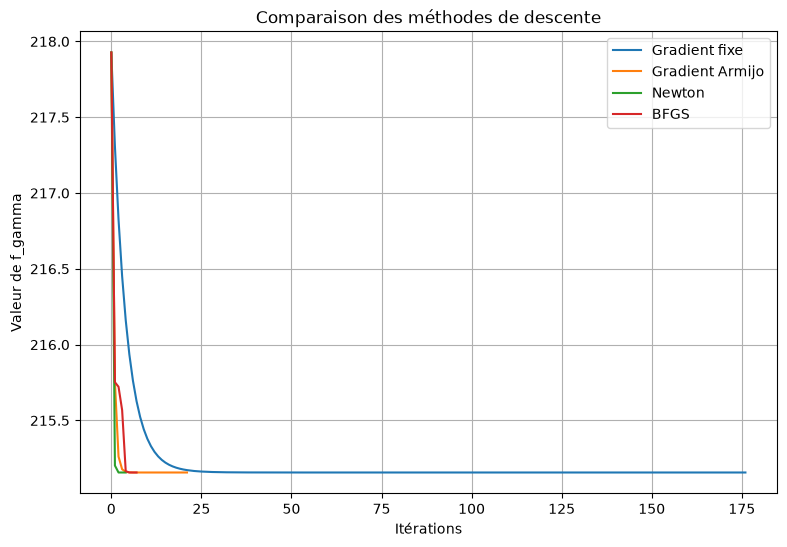

In [57]:
gamma = 0.1
plt.figure(figsize=(9, 6))

for nom, methode in methodes.items():
    x_opt, hist = methode(x0, gamma)

    plt.plot(hist, label=nom)

plt.xlabel("Itérations")
plt.ylabel("Valeur de f_gamma")
plt.title("Comparaison des méthodes de descente")
plt.legend()
plt.grid()
plt.show()